# Apartment price prediction with linear regression
Completed tutorial and all five independent exercises.

Predict price in **thousands of PLN** from area in **m²** using six supplied observations.
Source: [PRO-D-PJATK tutorial](https://github.com/PRO-D-PJATK/tutorials/tree/main/google-colab-linear-regression).

In Colab, choose **Runtime → Run all**. Upload `apartments.csv` to the runtime, or use the embedded copy of the supplied data below. No network download is needed for the data.


In [1]:
from pathlib import Path
from io import StringIO
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures
from sklearn.pipeline import make_pipeline
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import LeaveOneOut, cross_val_predict

plt.style.use('seaborn-v0_8-whitegrid')
pd.options.display.float_format = '{:.3f}'.format


## 1. Load and inspect the CSV
The fallback is an exact copy of the six rows in the assignment. Prices are not in individual PLN.


In [2]:
csv_path = Path('apartments.csv')
sample_csv = "area_m2,price_thousands_pln\n35,310\n50,395\n65,470\n80,560\n100,670\n120,770\n"
df = pd.read_csv(csv_path if csv_path.exists() else StringIO(sample_csv))
assert list(df.columns) == ['area_m2', 'price_thousands_pln']
assert not df.isna().any().any()
assert (df['area_m2'] > 0).all()
display(df)


,area_m2,price_thousands_pln
0,35,310
1,50,395
2,65,470
3,80,560
4,100,670
5,120,770


## 2. Separate the feature and target, then train
`X` is a two-dimensional DataFrame. `y` contains prices. Here “split” means separating the feature from the target. We fit all six observations for the tutorial, and later evaluate with leave-one-out cross-validation.


In [3]:
X = df[['area_m2']]
y = df['price_thousands_pln']
linear = LinearRegression().fit(X, y)
print(f'Price (thousands PLN) = {linear.coef_[0]:.6f} × area (m²) + {linear.intercept_:.6f}')


Price (thousands PLN) = 5.445000 × area (m²) + 120.791667


## 3. Visualize the regression and save a PNG
The line is drawn only within the observed area range.


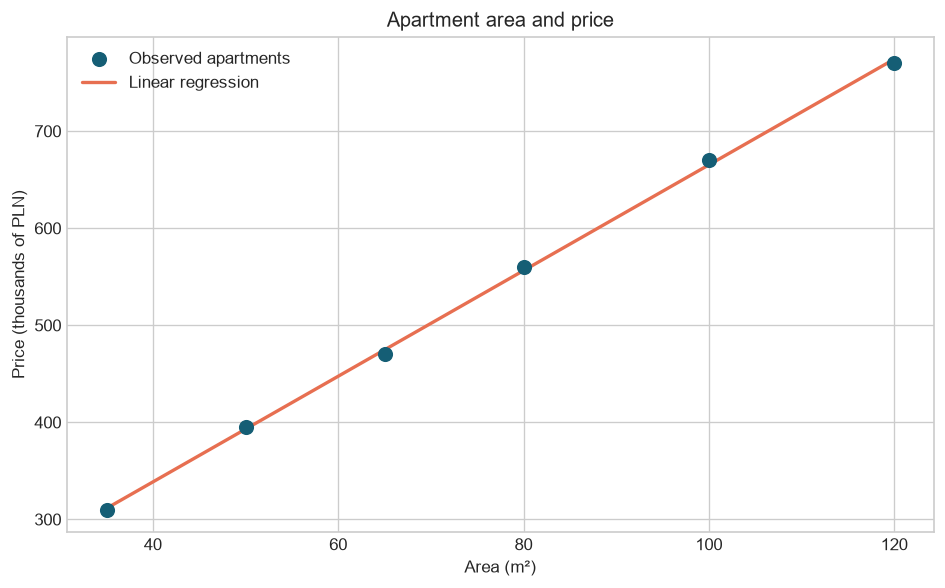

In [4]:
grid = pd.DataFrame({'area_m2': np.linspace(X['area_m2'].min(), X['area_m2'].max(), 300)})
fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(X['area_m2'], y, color='#155e75', s=65, label='Observed apartments', zorder=3)
ax.plot(grid['area_m2'], linear.predict(grid), color='#e76f51', label='Linear regression', linewidth=2)
ax.set(xlabel='Area (m²)', ylabel='Price (thousands of PLN)', title='Apartment area and price')
ax.legend()
fig.tight_layout()
plt.savefig('regression.png', dpi=180, bbox_inches='tight')
plt.show()


## 4. Predict prices for 40, 60 and 80 m²


In [5]:
new_areas = pd.DataFrame({'area_m2': [40, 60, 80]})
predictions = new_areas.copy()
predictions['predicted_price_thousands_pln'] = linear.predict(new_areas)
predictions['predicted_price_pln'] = predictions['predicted_price_thousands_pln'] * 1000
display(predictions)
predictions.to_csv('predictions.csv', index=False)


,area_m2,predicted_price_thousands_pln,predicted_price_pln
0,40,338.592,338591.667
1,60,447.492,447491.667
2,80,556.392,556391.667


## 5. Exercise: price per square metre
Convert thousands of PLN to PLN before dividing by area, so `price_per_m2` is in **PLN/m²**.


,area_m2,price_thousands_pln,price_per_m2
0,35,310,8857.143
1,50,395,7900.000
2,65,470,7230.769
3,80,560,7000.000
4,100,670,6700.000
5,120,770,6416.667


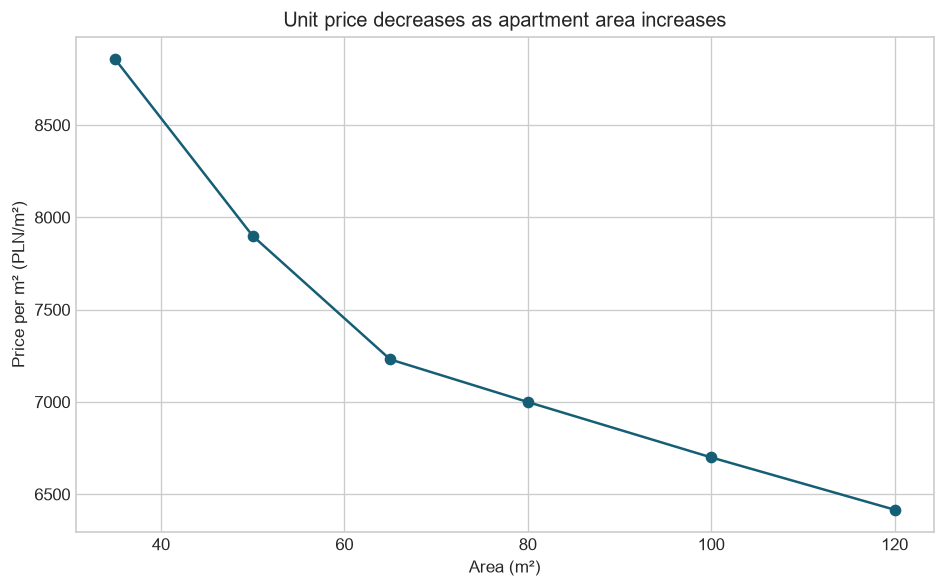

In [6]:
df['price_per_m2'] = df['price_thousands_pln'] * 1000 / df['area_m2']
display(df)
fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(df['area_m2'], df['price_per_m2'], 'o-', color='#155e75')
ax.set(xlabel='Area (m²)', ylabel='Price per m² (PLN/m²)', title='Unit price decreases as apartment area increases')
fig.tight_layout()
fig.savefig('price_per_m2.png', dpi=180, bbox_inches='tight')
plt.show()
df.to_csv('apartments_analysis.csv', index=False)


## 6. Exercises: errors and a second, squared feature
The polynomial model uses both `area_m2` and `area_m2²`. Training error measures fit to known observations. Leave-one-out (LOO) predictions are made by training on five rows and predicting the remaining row, repeated six times. Lower training error alone does not prove better generalization.

MAE and RMSE are in thousands of PLN. MSE is in squared thousands of PLN. R² is dimensionless.


In [7]:
quadratic = make_pipeline(PolynomialFeatures(degree=2, include_bias=False), LinearRegression())
quadratic.fit(X, y)
rows = []
for name, model in [('Linear', linear), ('Quadratic', quadratic)]:
    train_pred = model.predict(X)
    loo_pred = cross_val_predict(model, X, y, cv=LeaveOneOut())
    rows.append({'model': name,
                 'training_MAE': mean_absolute_error(y, train_pred),
                 'training_MSE': mean_squared_error(y, train_pred),
                 'training_RMSE': np.sqrt(mean_squared_error(y, train_pred)),
                 'training_R2': r2_score(y, train_pred),
                 'LOO_MAE': mean_absolute_error(y, loo_pred),
                 'LOO_MSE': mean_squared_error(y, loo_pred),
                 'LOO_RMSE': np.sqrt(mean_squared_error(y, loo_pred))})
metrics = pd.DataFrame(rows).set_index('model')
display(metrics)
metrics.to_csv('model_metrics.csv')
q = quadratic.named_steps['linearregression']
print(f'Quadratic: price = {q.intercept_:.6f} + {q.coef_[0]:.6f} × area + {q.coef_[1]:.6f} × area²')
better = metrics['LOO_MAE'].idxmin()
print(f'Lower leave-one-out MAE on these six observations: {better}')


Quadratic: price = 109.443152 + 5.784772 × area + -0.002189 × area²
Lower leave-one-out MAE on these six observations: Linear


,training_MAE,training_MSE,training_RMSE,training_R2,LOO_MAE,LOO_MSE,LOO_RMSE
model,,,,,,,
Linear,3.425,13.451,3.668,0.999,5.336,34.548,5.878
Quadratic,2.769,10.938,3.307,1.000,6.589,63.439,7.965


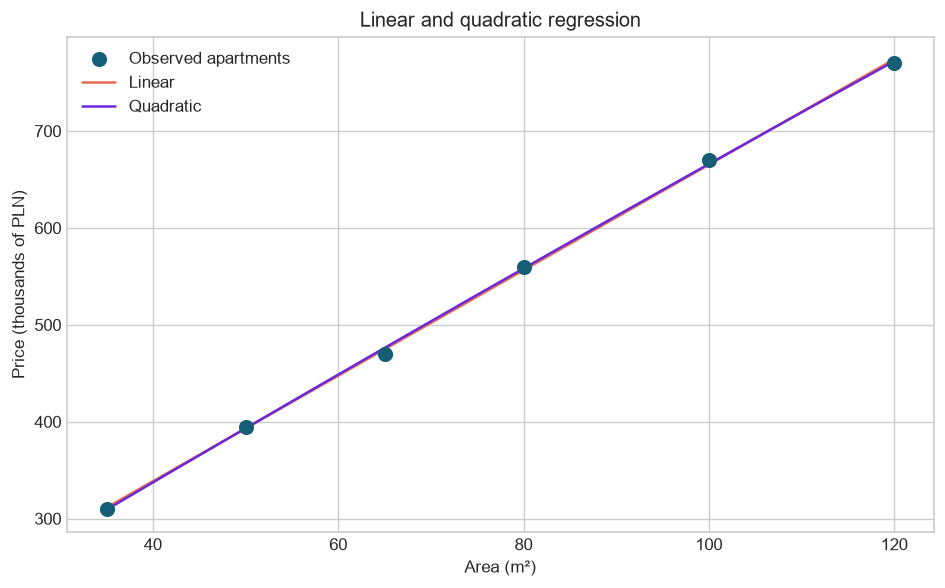

In [8]:
fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(X['area_m2'], y, s=65, color='#155e75', label='Observed apartments', zorder=3)
ax.plot(grid['area_m2'], linear.predict(grid), color='#e76f51', label='Linear')
ax.plot(grid['area_m2'], quadratic.predict(grid), color='#6d28d9', label='Quadratic')
ax.set(xlabel='Area (m²)', ylabel='Price (thousands of PLN)', title='Linear and quadratic regression')
ax.legend()
fig.tight_layout()
fig.savefig('model_comparison.png', dpi=180, bbox_inches='tight')
plt.show()


## 7. Interpretation
Prices increase with area, while price per m² decreases across the supplied sample. The linear slope measures the change in total price for one additional square metre. The intercept is a mathematical fit parameter: a zero-area apartment is outside the data range and has no useful interpretation here.

Compare the table's training errors and LOO errors before selecting a model. Only six illustrative observations are available, so the comparison is unstable and does not establish real housing-market accuracy. The data omit location, condition and other price drivers. Use predictions as an educational example and avoid extrapolating outside 35–120 m².

## Submission
Create `Colaboratory_<student-number>` in the `PRO-D-PJATK` organization, upload the project files and submit the repository link in the Teams assignment.
